---
title: Figure 5, kinematics over the trial
subtitle: MLAI - Visual uncertainty and task demands shape active sensing strategies in mice
authors:
  - name: C. Benquet
  - name: T. Sainsbury
venue: Current Biology
doi: 10.1016/j.cub.2026.06.011
github: https://github.com/MMathisLab/FreelyMovingVR4Mice
source_url: https://github.com/MMathisLab/FreelyMovingVR4Mice/blob/main/dj_pipeline/notebooks/Paper_figures/Figure_5b_decision.ipynb
---

:::{admonition} Contributed example
:class: note

- **Lab:** Mathis Lab of Adaptive Intelligence, EPFL
- **Source:** [FreelyMovingVR4Mice, `Figure_5b_decision.ipynb`](https://github.com/MMathisLab/FreelyMovingVR4Mice/blob/main/dj_pipeline/notebooks/Paper_figures/Figure_5b_decision.ipynb)
- **Publication:** Benquet C\*, Sainsbury T\*, Bruneau L, Lin Y, Cai C, Popova M, Ponder K, Ntanavara L, Froebe R, Tan Z, Fahey P, Franke K, Franco LM, Jones K, Chen Y, Keller R, Pitkow X, Niell CM, Tolias AS, Mathis MW (2026). Visual uncertainty and task demands shape active sensing strategies in mice. *Current Biology*. [doi:10.1016/j.cub.2026.06.011](https://doi.org/10.1016/j.cub.2026.06.011)
- **Permission:** Provided by the first author, Celia Benquet.
- **Changes:** Cells 4–7 (imports, data loading) and 9–12 (kinematics panels) only, code and saved outputs unchanged. Removed: environment and database-connection cells, and the cells for the other panels.
:::

Kinematics over the trial, by aperture.

:::{note}
The data come from the VR4Mice DataJoint database, so the cells are shown with their saved outputs; the database is available from the paper's data release.
:::

(sec-load)=
## Load the data

Imports, task selection (`contrast_white_target`, `multi_occlusion`), included sessions, and their interpolated trajectories.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from vr4mice.analysis import plotting
from vr4mice.schema import base_analysis
from vr4mice.analysis.analysis import style
from vr4mice.schema.interpolated_trajectories import InterpolatedTrials
from vr4mice.schema.decision import InclusionStatus, ExperimentMember, LabelSet, Label, PredictionModel10Windows, DecisionPoints10Windows

from statsmodels.stats.anova import AnovaRM
import scipy.stats as stats
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from vr4mice.analysis import regression

from scipy.stats import pearsonr
from mpl_toolkits.axes_grid1 import make_axes_locatable

from vr4mice.analysis.stats import get_multi_p_values_global, get_multi_p_values_binned, plot_aperture_heatmap

style()

save_fig_path = "notebooks/Paper_figures/Figure_output/"

In [5]:
task_type_key = {"set_name": "contrast_white_target",
                 "stage_name": "multi_occlusion",}

In [6]:
sessions_list = list(
                (InclusionStatus * ExperimentMember & {"included": 1} & task_type_key).fetch(
                    "dataset"
                )
            )

len(sessions_list)

25

In [7]:
# This takes a while to fetch because we need to fetch data for all trials
dataset_list = []
for d in sessions_list:
    print(d)
    try:
        dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))
    except Exception as err:
        print(err, " dataset missing")
interpolated_df = pd.concat(dataset_list)
interpolated_df["mouse_name"] = interpolated_df.dataset.str.split("_").str[0]

31726_2025-03-27_1
31726_2025-03-28_1
31728_2025-03-11_1
31728_2025-03-14_1
J729_2024-12-11_1
J729_2024-12-12_1
J729_2024-12-13_1
J729_2024-12-15_1
Jacana_2024-08-21_1
Jacana_2024-08-22_1
Kiwi_2024-08-19_1
Kiwi_2024-08-20_1
Kiwi_2024-08-21_1
Lemming_2024-08-14_1
Lemming_2024-08-15_1
Lemming_2024-08-19_1
Nightingale_2024-08-15_1
Nightingale_2024-08-16_1
Nightingale_2024-08-21_1
Nightingale_2024-08-22_1
Oribi_2024-08-26_1
Oribi_2024-08-27_1
Oribi_2024-08-29_1
Pheasant_2024-08-26_1
Pheasant_2024-08-28_1


(sec-kinematics)=
## Kinematics over the trial

Data from [](#sec-load). Lines: mean across sessions. Bands: standard error. Colour: aperture.

### Combined velocity

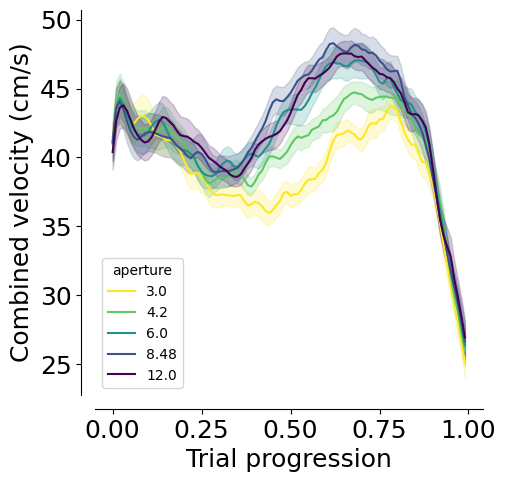

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax = ax
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_length"], as_index=False
).mean(numeric_only=True)

mean_mouse.sort_values("aperture", inplace=True)
mean_mouse["aperture"] = mean_mouse.aperture.astype("str")

sns.lineplot(
    data=mean_mouse,
    x="trial_length",
    y="velocity",
    palette=plotting.colors_multi_aperture,
    hue="aperture",
    errorbar="se",
    ax=ax,
)

sns.despine(offset=10)
ax.set_xlabel("Trial progression")
ax.set_ylabel("Combined velocity (cm/s)")
plt.savefig(save_fig_path + "figure5_velocity.svg", transparent=False)

### Velocity, tortuosity and distance to port

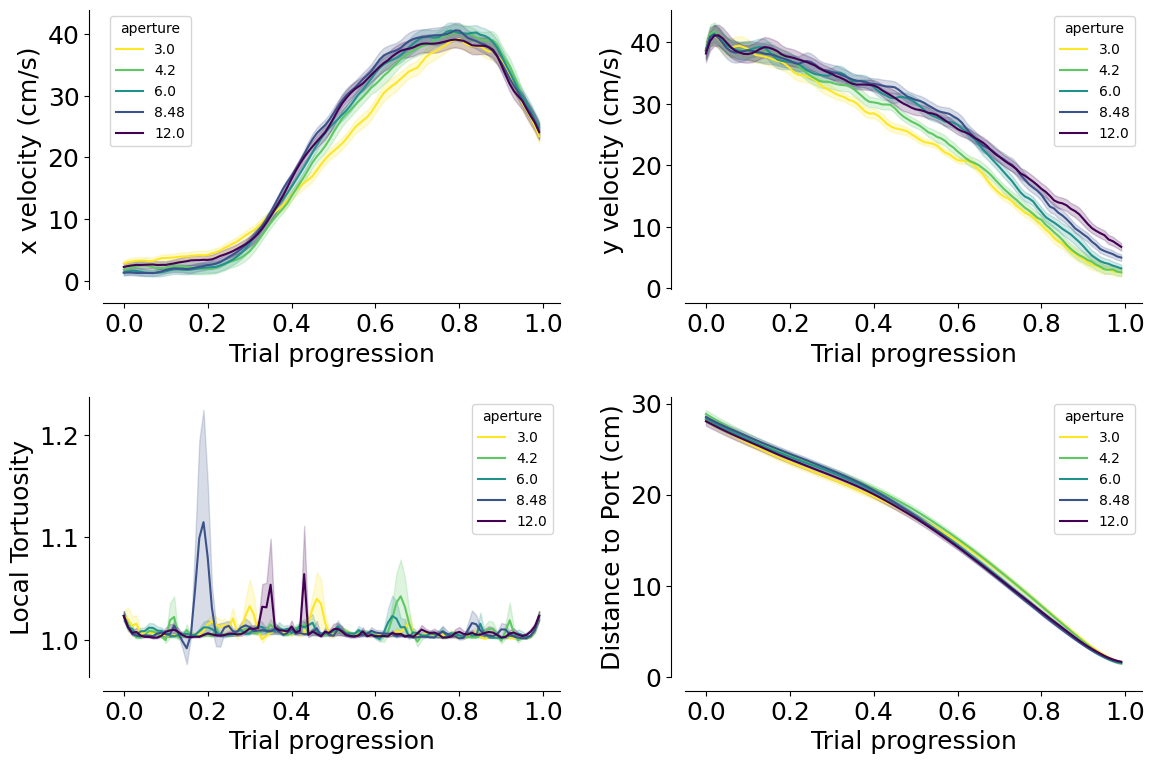

In [10]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

for (i, label), label_str in zip(enumerate(
    ["velocity_x_fliped", "velocity_y", "local_tortuosity", "distance_to_choice"]
), ["x velocity (cm/s)", "y velocity (cm/s)", "Local Tortuosity", "Distance to Port (cm)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=(
            plotting.colors_aperture[:2]
            if len(mean_mouse.aperture.unique()) == 2
            else plotting.colors_multi_aperture
        ),
        hue="aperture",
        errorbar="se",
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)
    
plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure5_velocity_tortuosity_distance.svg", bbox_inches="tight", transparent=True)

### Running direction and head-body angle

Line style: choice (`trial_left_choice`).

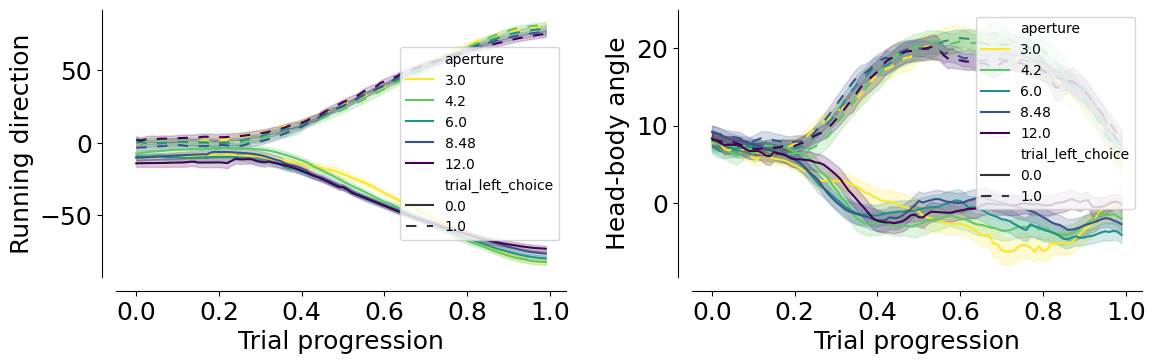

In [11]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax = ax.flatten()

dash_styles = {
    mean_mouse.trial_left_choice.unique()[0]: "",         # Solid
    mean_mouse.trial_left_choice.unique()[1]: (5, 5)      # Dashed
}

for (i, label), label_str in zip(enumerate(["heading_dir", "head_angle"]), 
                                 ["Running direction", "Head-body angle"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=plotting.colors_choice[::-1]
        if len(mean_mouse.aperture.unique()) == 2
        else plotting.colors_multi_aperture,
        hue="trial_left_choice"
        if len(mean_mouse.aperture.unique()) == 2
        else "aperture",
        style=(
            "aperture"
            if len(mean_mouse.aperture.unique()) == 2
            else "trial_left_choice"
        ),
        dashes=dash_styles,
        errorbar="se",
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)


plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure5_heading_dir_head_angle.svg", bbox_inches="tight", transparent=True)

### Running direction and head-body angle, as cosine and sine

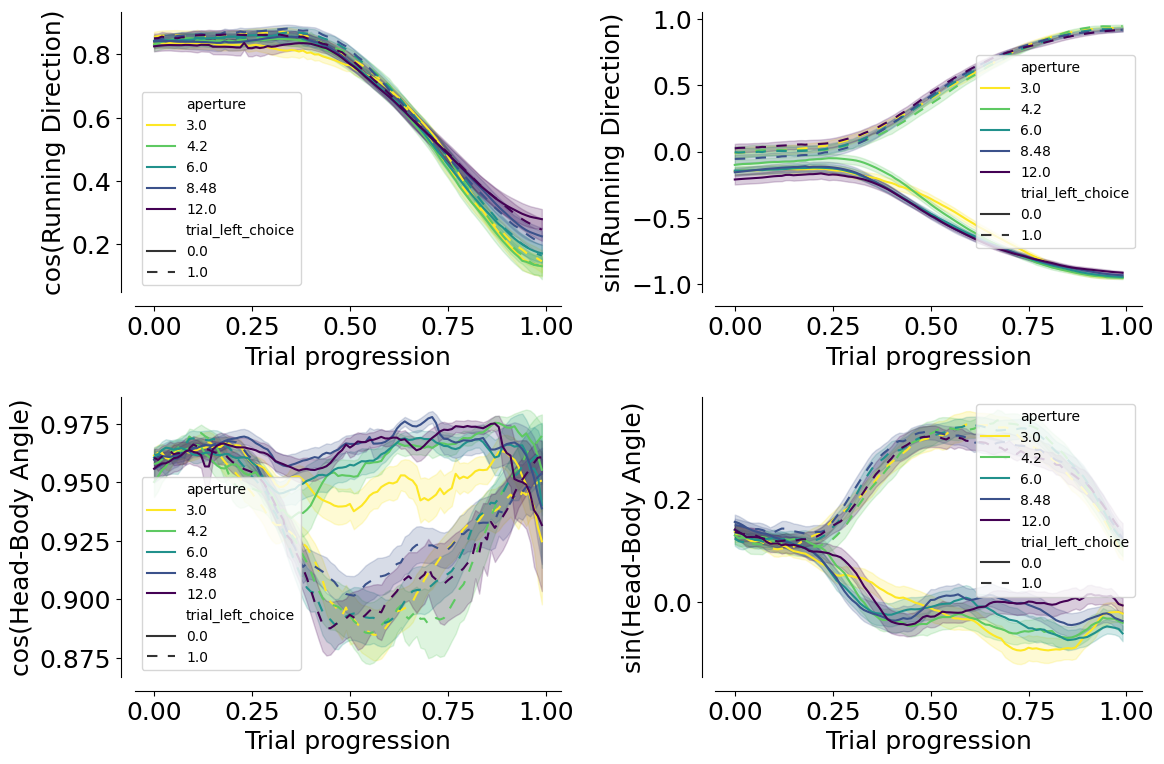

In [12]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

dash_styles = {
    mean_mouse.trial_left_choice.unique()[0]: "",         # Solid
    mean_mouse.trial_left_choice.unique()[1]: (5, 5)      # Dashed
}

for (i, label), label_str in zip(enumerate(
    ["heading_dir_cos", "heading_dir_sin", "head_angle_cos", "head_angle_sin"]
), ["cos(Running Direction)", "sin(Running Direction)", "cos(Head-Body Angle)", "sin(Head-Body Angle)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=plotting.colors_choice[::-1]
        if len(mean_mouse.aperture.unique()) == 2
        else plotting.colors_multi_aperture,
        hue="trial_left_choice"
        if len(mean_mouse.aperture.unique()) == 2
        else "aperture",
        style=(
            "aperture"
            if len(mean_mouse.aperture.unique()) == 2
            else "trial_left_choice"
        ),
        errorbar="se",
        ax=ax[i],
        dashes=dash_styles,
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)


plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure5_heading_dir_head_angle_cos_sin.svg", bbox_inches="tight", transparent=True)